# Introduction

# Part 1: Dataset

## 1.1. Importing Libraries

We will install the modules necessary for processing and splitting the dataset, as well as training different models.

In [1]:
%pip install xgboost scikit-optimize                # for BayesSearchCV

# Data Processing
import numpy as np
import pandas as pd
import re
import ast
import json

# Models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Data Transformation
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, TargetEncoder, StandardScaler

# Cross-Validation
from skopt import BayesSearchCV
from skopt.space import Real, Integer, Categorical

# Model Evaluation
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# Plot
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px

## 1.2. Importing Dataset

We will pull our main table from the [OpenAlex API](https://docs.openalex.org), which is under CC0, using this [script](https://colab.research.google.com/drive/1fW5ZYzsfhuQTLiwYT-Fjuk_LviddvUXX?usp=sharing). We then join it with two other tables extracted from the Hugging Face API, `open-index/open-arxiv` (CC0) and [Papers with Code](https://huggingface.co/datasets/pwc-archive/links-between-paper-and-code) (CC-BY-SA), using this [script](https://colab.research.google.com/drive/1ASUN5w36f7FC300-ONni5fg_OeIWEmCp?usp=sharing).

In [2]:
# Load the joined dataset
papers_df = pd.read_parquet("https://www.dropbox.com/scl/fi/jolt6kfbslvla17m234pi/full_papers.parquet?rlkey=ohjrwo5oi8q1fsahue3gy9ccs&st=v72ugyvb&dl=1")

## 1.3. Analyzing Dataset

We will first analyze the structure of the data, including the data types and missing values.

In [3]:
# View the first 5 samples
papers_df.head(5)

,id,doi,title,abstract_inverted_index,publication_date,publication_year,counts_by_year,authorships,institutions_distinct_count,countries_distinct_count,...,language,arxiv_id,categories,versions,comments,journal-ref,update_date,license,num_repositories,has_code
0,https://openalex.org/W3003257820,https://doi.org/10.1038/s41592-019-0686-2,SciPy 1.0: fundamental algorithms for scientif...,"{'SciPy': [0, 18, 65], 'is': [1], 'an': [2, 56...",2020-02-03,2020,"[{'year': 2026, 'cited_by_count': 7041}, {'yea...","[{'author_position': 'first', 'author': {'id':...",84,18,...,en,1907.10121,cs.MS cs.DS cs.SE physics.comp-ph,"[{""version"":""v1"",""created"":""Tue, 23 Jul 2019 2...",Article source data is available here:\n http...,None,2020-09-18,http://creativecommons.org/licenses/by/4.0/,1,1
1,https://openalex.org/W2963163009,https://doi.org/10.1109/cvpr.2018.00474,MobileNetV2: Inverted Residuals and Linear Bot...,"{'In': [0], 'this': [1, 133, 143], 'paper': [2...",2018-06-01,2018,"[{'year': 2026, 'cited_by_count': 3194}, {'yea...","[{'author_position': 'first', 'author': {'id':...",1,1,...,en,1801.04381,cs.CV,"[{""version"":""v1"",""created"":""Sat, 13 Jan 2018 0...",,None,2019-03-25,http://arxiv.org/licenses/nonexclusive-distrib...,159,1
2,https://openalex.org/W3035965352,https://doi.org/10.1038/s41586-020-2649-2,Array programming with NumPy,"{'Abstract': [0], 'Array': [1], 'programming':...",2020-09-16,2020,"[{'year': 2026, 'cited_by_count': 4947}, {'yea...","[{'author_position': 'first', 'author': {'id':...",18,7,...,en,2006.10256,cs.MS stat.CO,"[{""version"":""v1"",""created"":""Thu, 18 Jun 2020 0...",,None,2020-09-22,http://creativecommons.org/licenses/by/4.0/,1,1
3,https://openalex.org/W2964309882,https://doi.org/10.1007/978-3-030-01234-2_49,Encoder-Decoder with Atrous Separable Convolut...,,2018-01-01,2018,"[{'year': 2026, 'cited_by_count': 2340}, {'yea...","[{'author_position': 'first', 'author': {'id':...",1,1,...,en,1802.02611,cs.CV,"[{""version"":""v1"",""created"":""Wed, 7 Feb 2018 19...",ECCV 2018 camera ready,None,2018-08-24,http://arxiv.org/licenses/nonexclusive-distrib...,78,1
4,https://openalex.org/W3030520226,https://doi.org/10.1007/978-3-030-58452-8_13,End-to-End Object Detection with Transformers,,2020-01-01,2020,"[{'year': 2026, 'cited_by_count': 2756}, {'yea...","[{'author_position': 'first', 'author': {'id':...",2,2,...,en,2005.12872,cs.CV,"[{""version"":""v1"",""created"":""Tue, 26 May 2020 1...",,None,2020-05-29,http://creativecommons.org/publicdomain/zero/1.0/,37,1


### 1.3.1. General View

In [4]:
# View the data types of each feature
papers_df.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122136 entries, 0 to 122135
Data columns (total 29 columns):
 #   Column                       Non-Null Count   Dtype 
---  ------                       --------------   ----- 
 0   id                           122136 non-null  object
 1   doi                          122066 non-null  object
 2   title                        122136 non-null  object
 3   abstract_inverted_index      122136 non-null  object
 4   publication_date             122136 non-null  object
 5   publication_year             122136 non-null  int64 
 6   counts_by_year               122136 non-null  object
 7   authorships                  122136 non-null  object
 8   institutions_distinct_count  122136 non-null  int64 
 9   countries_distinct_count     122136 non-null  int64 
 10  referenced_works_count       122136 non-null  int64 
 11  referenced_works             122136 non-null  object
 12  primary_topic                122136 non-null  object
 13  topics        

**Initial Observations**:
- `journal-ref` is empty, so we can drop this column completely.
- Other features that have some missing values: `doi`, `versions`, `update_date`, and `license`
  - `publication_date` and `update_date` are stored as string instead of a datetime object

### 1.3.2. Checking Duplicates

Check that the dataset doesn't contain multiple records for the same arXiv ID and that the join didn't duplicate papers.

In [5]:
# Check for records that share the same arXiv ID
print("Total rows:", len(papers_df))
print("Unique arXiv IDs:", papers_df["arxiv_id"].nunique())
print("Duplicate arXiv IDs:", papers_df["arxiv_id"].duplicated().sum())

# Check for duplicate rows
papers_df[papers_df.duplicated(keep=False)]

Total rows: 122136
Unique arXiv IDs: 122136
Duplicate arXiv IDs: 0


,id,doi,title,abstract_inverted_index,publication_date,publication_year,counts_by_year,authorships,institutions_distinct_count,countries_distinct_count,...,language,arxiv_id,categories,versions,comments,journal-ref,update_date,license,num_repositories,has_code


### 1.3.3. Data Type of Nested Columns

`.info()` only give the data type `object` for non-numerical features. We will closely examine the data type these columns, especially those with nested columns.

In [6]:
columns = ["abstract_inverted_index", "counts_by_year", "authorships",
           "referenced_works", "primary_topic", "topics", "versions", "open_access"]

for col in columns:
    print(f"{col}: {type(papers_df[col].iloc[0])}")

abstract_inverted_index: <class 'str'>
counts_by_year: <class 'str'>
authorships: <class 'str'>
referenced_works: <class 'str'>
primary_topic: <class 'str'>
topics: <class 'str'>
versions: <class 'str'>
open_access: <class 'str'>


**Issue**: The above features are supposed to be a `list` of values, but they are stored as string.

### 1.3.4. Missing Values

Even though the `categories` and `comments` columns contain no null values, since they are stored as string, the null values may be represented as an empty string.

In [7]:
print('categories')
print(f"Empty strings: {(papers_df['categories'] == "").sum()}\n")
print('comments')
print(f"Empty strings: {(papers_df['comments'] == "").sum()}")

categories
Empty strings: 39

comments
Empty strings: 46894


### 1.3.5. Unique Values

We will examine the number of unique values of non-numerical columns to decide a preprocessing method.

In [8]:
# See the number of unique values for each feature in the dataset
for col in papers_df:
    print(f'{col}: {papers_df[col].nunique():,}')

id: 122,136
doi: 122,065


title: 122,096


abstract_inverted_index: 108,279
publication_date: 1,096
publication_year: 3
counts_by_year: 65,142


authorships: 120,659
institutions_distinct_count: 37
countries_distinct_count: 19
referenced_works_count: 372


referenced_works: 112,169
primary_topic: 49,397


topics: 107,431
open_access: 122,135


locations: 122,136
locations_count: 26


primary_location: 122,136
type: 22
language: 22
arxiv_id: 122,136
categories: 10,156
versions: 122,064
comments: 52,172
journal-ref: 0
update_date: 2,700
license: 8
num_repositories: 75
has_code: 2


We found several high-cardinality, non-numerical features that can cause issues during the one-hot encoding procedure: `abtract_inverted_index`, `publication_date`, `counts_by_year` (**TARGET**), `authorships`, `referenced_works`, `primary_topic`, `topics`, `open_access`, `locations`, `primary_location`, `categories`, `versions`, `comments`, and `update_date`.

To fix this issue, we will drop non-numerical features that do not contain meaningful information or convert them into numerical features.

# Part 2: Cleaning Dataset

## 2.1. Dropping Columns

We will drop the following columns:
- `journal-ref` - Empty column
- `id`, `doi`, and `arxiv_id` - Unique identifiers that are unnecessary data and can cause noise
- `update_date`- Represents the latest metadata update, not the initial submission date
- `locations` - This column was used to extract a paper's arXiv ID, but `locations_count` is a sufficient numerical representation of it
- `referenced_works` - Its detailed information is unnecessary, as the `referenced_works_count` is a sufficient numerical representation of it

In [9]:
cleaned_papers_df = papers_df.copy()

# Drop unnecessary columns
cleaned_papers_df.drop(labels=['journal-ref', 'id', 'doi', 'arxiv_id', 'update_date',
                               'locations', 'referenced_works'],
                       axis=1, inplace=True)

60

## 2.2. Feature Engineering

Since there exist high-cardinality, non-numerical features, we will engineer features from them to resolve the issues.

**Note**: Since there exist nested columns that are stored as strings, we need to use `ast.literal_eval()` to convert them to lists to be used for analysis, extraction, and engineering features.

### 2.2.1. cites_3yr

As mentioned above, our target, `counts_by_year`, is a list of citations, but it is stored as a string. Hence, we will parse this column into lists.

In [10]:
cleaned_papers_df['counts_by_year'] = cleaned_papers_df['counts_by_year'].apply(lambda x: ast.literal_eval(x))

Compute `cites_3yr` by extracting the year-to-citation-count mapping and summing the three relevant years.

<u>Note:</u> If OpenAlex omits a year in `counts_by_year`, this means that the paper received **zero** citations in that year.

In [11]:
def calculate_cites_3yr(row):
    counts = row["counts_by_year"]
    year = row["publication_year"]

    if pd.isna(year):
        return np.nan
    citation_dict = {item["year"]: item["cited_by_count"] for item in counts}
    return sum(citation_dict.get(y, 0) for y in range(int(year), int(year) + 3))

cleaned_papers_df["cites_3yr"] = cleaned_papers_df.apply(calculate_cites_3yr, axis=1)
cleaned_papers_df.drop('counts_by_year', axis=1, inplace=True)

### 2.2.2. Date

Publication Month

In addition to the publication year, we also want to use a paper's publication month as a predictor, which is extracted from `publication_date`. This date affects when the paper gains official visibility and starts accumulating formal citations.

In [12]:
# Convert strings into datetime objects
cleaned_papers_df["publication_date"] = pd.to_datetime(cleaned_papers_df["publication_date"], errors="coerce")

# Extract the month from the datetime objects
cleaned_papers_df["publication_month"] = cleaned_papers_df["publication_date"].dt.month

Submission Month

The `versions` column may contain a list of version records with timestamps. Extract the first version, which will contain the month of the submission.

Many field have massive spikes in submissions right before major conference deadlines. Papers submitted during these rush periods might have different citation trajectories or characteristics than off-season submissions.

In [13]:
def get_first_submission(x):
    if not isinstance(x, str) or pd.isna(x):
        return None
    versions = ast.literal_eval(x)
    if versions:
        return versions[0].get("created")
    return None

first_submission = cleaned_papers_df['versions'].apply(get_first_submission)
first_submission_date = pd.to_datetime(first_submission, errors="coerce")
cleaned_papers_df["submission_month"] = first_submission_date.dt.month

cleaned_papers_df.drop('versions', axis=1, inplace=True)

### 2.2.3. Time Gap

Using `publication_date` and `first_submission_date`, we can derived the `time_to_publish`. A long gap between submission might indicate a rigorous peer-review process, multiple revisions, or a prestigious journal, which could be a strong predictor.

In [14]:
cleaned_papers_df['time_to_publish'] = (cleaned_papers_df['publication_date'] - first_submission_date).dt.days

cleaned_papers_df.drop('publication_date', axis=1, inplace=True)

Check whether `time_to_publish` contains negative values.

In [15]:
print(f"Negative Time Gap: {len(cleaned_papers_df[cleaned_papers_df['time_to_publish'] < 0])}")

Negative Time Gap: 76339


Because variable `first_submission_date` comes from the paper's first arXiv version (extracted from Hugging Face) and `publication_date` comes from OpenAlex (the official journal/conference date), a negative value means that the paper was officially published **before** it was uploaded to arXiv (~62.5%). This happens frequently when researchers upload "post-prints" to arXiv after their paper has already been accepted or published, or when a conference date precedes the arXiv upload.

To capture these distinct timing dynamics and avoid passing raw negative days into the model, we engineer two separate, non-negative features:
- `pub_after_arxiv_days` = This clips the time gap at a minimum of `0`. It measures the formal wait time from public preprint release on arXiv to official publication. For papers published before being posted to arXiv, this is reasonably treated as `0` days.
- `arxiv_after_pub_days` = This measures the delay in posting a paper to arXiv *after* it has already been officially published. This captures "post-print" posting behavior, which often has a different social or citation dynamic compared to preprints.

In [16]:
cleaned_papers_df['pub_after_arxiv_days'] = cleaned_papers_df['time_to_publish'].clip(lower=0)
cleaned_papers_df['arxiv_after_pub_days'] = (-cleaned_papers_df['time_to_publish']).clip(lower=0)

cleaned_papers_df.drop('time_to_publish', axis=1, inplace=True)

### 2.2.4. Authorships

OpenAlex `authorships` is a list of the authorship records (e.g., names, positions, institutions, countries). To represent the academic influence, diversity, and geographical footprint of a paper, we engineer the following features:
- `author_count` = The total number of co-authors on the paper. Larger collaboration networks may expand a paper's initial reach and increase citation probability.
- `has_company_author` = A binary flag (`1` or `0`) indicating whether at least one author is affiliated with an industry/company institution. Corporate backing and collaborative research can point to strong real-world applications or resources, often accelerating citation rates.
- `first_author_country` = The country of affiliation for the first author. This controls for regional publishing patterns, language familiarity, and geographically clustered academic networks.

In [17]:
authorships = cleaned_papers_df['authorships'].apply(ast.literal_eval)
cleaned_papers_df.drop('authorships', axis=1, inplace=True)

cleaned_papers_df["author_count"] = authorships.apply(lambda x: len(x))
cleaned_papers_df["has_company_author"] = authorships.apply(
    lambda a: int(any(i.get("type") == "company" for x in a for i in (x.get("institutions") or []))))
cleaned_papers_df["first_author_country"] = authorships.apply(
    lambda a: next((x["countries"][0] for x in a
                    if x.get("author_position") == "first" and x.get("countries")), "unknown"))

### 2.2.5. Title & Abstract Length

To capture paper complexity, readability, and information density, we extract text-length features:
- `title_length` = The number of words in the title. Shorter, punchier titles might be more memorable, while longer ones can be highly descriptive.
- `abstract_length` = Computed by reconstructively summing the length of word position indexes within `abstract_inverted_index`. Shorter abstracts might indicate concise summaries, whereas longer ones could signify highly detailed or interdisciplinary work.

In [18]:
# Title Length
cleaned_papers_df['title_length'] = cleaned_papers_df['title'].apply(lambda x: len(x.split()))
cleaned_papers_df.drop('title', axis=1, inplace=True)

# Abstract Length
def get_abstract_length(x):
    if not isinstance(x, str) or x == "":
        return 0
    abstract = ast.literal_eval(x)
    return sum(len(positions) for positions in abstract.values())

cleaned_papers_df['abstract_length'] = cleaned_papers_df['abstract_inverted_index'].apply(get_abstract_length)
cleaned_papers_df.drop('abstract_inverted_index', axis=1, inplace=True)

### 2.2.6. Category

To capture a paper's scientific domain and interdisciplinary scope, we engineer two features from the arXiv `categories`:
- `category_count` = The total number of subcategories a paper is tagged with. This measures its level of interdisciplinarity (e.g., crossing computer science with physics).
- `primary_category` = The first category in the listed tags, representing the primary home or focus of the paper.

In [19]:
cats = cleaned_papers_df["categories"].str.split()
cleaned_papers_df.drop('categories', axis=1, inplace=True)

cleaned_papers_df['category_count'] = cats.apply(lambda x: len(x))
cleaned_papers_df['primary_category'] = cats.str[0].fillna("unknown")

### 2.2.7. Venue

The `primary_location` dictionary provides information about where a paper was formally published. From this nested metadata, we extract the venue classification:
- `venue_type` = Represents the category of the publishing source (e.g., `'journal'`, `'repository'`, `'conference'`). Different publishing formats have distinct review standards, audience reaches, and propagation speeds, which strongly influence the long-term and short-term citation trajectories of the paper.

In [20]:
# Publisher / venue
primary_location = papers_df['primary_location'].apply(ast.literal_eval)
cleaned_papers_df['venue_type'] = primary_location.apply(lambda d: ((d or {}).get("source") or {}).get("type") or "unknown")

cleaned_papers_df.drop('primary_location', axis=1, inplace=True)

### 2.2.8. Topics & Primary Topic

These features capture the overall domain context and theme density defined by OpenAlex:
- `n_subfields` = Represents the number of unique subfields a paper spans based on its topic tags. This acts as a proxy for topic breadth.
- `primary_subfield` = The name of the main subfield associated with the paper's primary topic, helping the model learn field-specific citation baselines.

In [21]:
# Topics
topics = cleaned_papers_df['topics'].apply(ast.literal_eval)
cleaned_papers_df.drop('topics', axis=1, inplace=True)
cleaned_papers_df['n_subfields'] = topics.apply(lambda t: len({x["subfield"]["display_name"] for x in t if x.get("subfield")}))

# Primary Topic
primary_topic = cleaned_papers_df['primary_topic'].apply(ast.literal_eval)
cleaned_papers_df.drop('primary_topic', axis=1, inplace=True)
cleaned_papers_df["primary_subfield"] = primary_topic.apply(lambda x: x.get('subfield').get('display_name'))

### 2.2.9. Comments

The `comments` column contains unstructured metadata appended to the preprint submission. To leverage this unstructured text, we extract structural information:
- `page_count` = Extracted by searching for page-related patterns (e.g., "12 pages"). The overall length of a manuscript is a strong proxy for detail, density of information, and type of paper (such as brief communication vs. full-length monograph), which directly scales with citation frequency.

In [22]:
comments = cleaned_papers_df["comments"].fillna("")
cleaned_papers_df.drop('comments', axis=1, inplace=True)

cleaned_papers_df["page_count"] = pd.to_numeric(comments.str.extract(r"(\d+)\s*pages?", flags=re.I)[0])

### 2.2.10. Accessibility

Open access directly influences how easily other researchers can read and reference a manuscript. From the `open_access` nested metadata, we extract:
- `is_oa` = A binary flag indicating whether the paper is openly readable. Lowering paywall barriers is heavily associated with higher download rates and increased early-stage citation velocity.
- `oa_status` = Categorical classification of the open access path (e.g., gold, green, bronze, hybrid, closed). This helps capture publishing routes, publisher fees, and repository compliance patterns.
- `any_repository_has_fulltext` = A binary flag showing if a green open access version is archived elsewhere. This serves as a strong signal of manuscript discoverability outside of traditional publisher portals.

In [23]:
oa_cols = ["is_oa", "oa_status", "any_repository_has_fulltext"]

for col in oa_cols:
    cleaned_papers_df[col] = cleaned_papers_df["open_access"].apply(
        lambda x: (ast.literal_eval(x)).get(col)
    )
binary_cols = ['is_oa', 'any_repository_has_fulltext']
cleaned_papers_df[binary_cols] = cleaned_papers_df[binary_cols].astype("float64")

cleaned_papers_df.drop('open_access', axis=1, inplace=True)

### 2.2.11. Cleaning

In [24]:
cleaned_papers_df.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 122136 entries, 0 to 122135
Data columns (total 29 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   publication_year             122136 non-null  int64  
 1   institutions_distinct_count  122136 non-null  int64  
 2   countries_distinct_count     122136 non-null  int64  
 3   referenced_works_count       122136 non-null  int64  
 4   locations_count              122136 non-null  int64  
 5   type                         122136 non-null  object 
 6   language                     122136 non-null  object 
 7   license                      122096 non-null  object 
 8   num_repositories             122136 non-null  int64  
 9   has_code                     122136 non-null  int64  
 10  cites_3yr                    122136 non-null  int64  
 11  publication_month            122136 non-null  int32  
 12  submission_month             122097 non-null  float64
 13 

Since `page_count` is missing ~70% of its data, we will drop this column.

In [25]:
cleaned_papers_df.drop('page_count', axis=1, inplace=True)

We observed that `license` is missing 40 values, while `submission_month`, `pub_after_arxiv_days`, and `arxiv_after_pub_days` are missing 39 values. First, we will check whether the missing values overlap.

In [26]:
cols = ["license", "submission_month", "pub_after_arxiv_days", "arxiv_after_pub_days"]

print(cleaned_papers_df[cols].isna().sum())
print("\nMissing-value combinations:")
print(cleaned_papers_df[cols].isna().value_counts())

license                 40
submission_month        39
pub_after_arxiv_days    39
arxiv_after_pub_days    39
dtype: int64

Missing-value combinations:
license  submission_month  pub_after_arxiv_days  arxiv_after_pub_days
False    False             False                 False                   122096
True     True              True                  True                        39
         False             False                 False                        1
Name: count, dtype: int64


The `Missing-value combinations` table tells us that there are 39 papers (~0.03%) that are missing data for *all four* columns at the same time, so their timing information can’t be recovered. Imputing with their medians would invent values for a negligible gain, so we drop them and fill the one missing `license` row with "unknown" to be one-hot encoded later.

In [27]:
before = len(cleaned_papers_df)

# Drop the 39 rows where 4 features contained null values
# and fill the missing `license` with an "unknown" value
cleaned_papers_df = cleaned_papers_df.dropna(subset=["submission_month", "pub_after_arxiv_days"])
cleaned_papers_df["license"] = cleaned_papers_df["license"].fillna("unknown")

Check the cardinality of all features.

In [28]:
# List of categorical and numerical features to be used for model training
categorical_cols = ['type', 'language', 'license', 'oa_status', 'primary_subfield',
                    'primary_category', 'venue_type', 'first_author_country']
numerical_cols = [col for col in cleaned_papers_df if col not in categorical_cols
                  and col != 'cites_3yr']

In [29]:
# Check the number of unique values for categorical features in the dataset
for col in categorical_cols:
    print(f'{col}: {cleaned_papers_df[col].nunique():,}')

type: 22
language: 22
license: 9
oa_status: 5
primary_subfield: 11
primary_category: 145
venue_type: 6
first_author_country: 126


Observations:
- The only high-cardinality features are `primary_category` and `first_author_country`
- The remaining categorical features are of low-cardinality, so we can one-hot encode them

Even if they are of high-cardinality, these features contain valuable information which can influence the number of citations a paper receive. Hence, we will group categories and countries with low-frequency (e.g., values that appear in 100 or less papers) into a single label "Other". This approach helps control feature explosion during one-hot encoding, prevents overfitting on rare categories, and preserves the predictive value of highly frequent levels.

In [30]:
counts = cleaned_papers_df['first_author_country'].value_counts()
print(counts.head(10))

cleaned_papers_df['first_author_country'] = (
    cleaned_papers_df['first_author_country']
    .where(cleaned_papers_df['first_author_country'].map(counts) >= 100, "Other")
)
print(f"first_author_country: {cleaned_papers_df['first_author_country'].nunique()}")

first_author_country
unknown    28048
US         27639
CN         12339
DE          6399
GB          5821
FR          3675
CA          3571
IN          2777
JP          2579
AU          2423
Name: count, dtype: int64
first_author_country: 50


In [31]:
counts = cleaned_papers_df['primary_category'].value_counts()
print(counts.head(10))

cleaned_papers_df['primary_category'] = (
    cleaned_papers_df['primary_category']
    .where(cleaned_papers_df['primary_category'].map(counts) >= 100, "Other")
)
print(f"primary_category: {cleaned_papers_df['primary_category'].nunique()}")

primary_category
cs.CV       19505
cs.LG       17428
cs.CL       10808
quant-ph     7804
cs.CR        5005
cs.DC        3268
cs.AI        3237
cs.IT        3212
stat.ML      3195
cs.DS        3142
Name: count, dtype: int64
primary_category: 73


Since the cardinality of these two categorical features are low enough, we can one-hot encode them when training our models.

We will now check the distribution of the unique values in each of the other low-cardinality categorical features.

In [32]:
for col in ["type", "language", "license", "oa_status", "venue_type"]:
    print(col, cleaned_papers_df[col].value_counts(normalize=True).head(3).round(3).to_dict())

type {'preprint': 0.476, 'conference-paper': 0.266, 'article': 0.247}
language {'en': 0.998, 'lv': 0.001, 'fr': 0.0}
license {'http://arxiv.org/licenses/nonexclusive-distrib/1.0/': 0.888, 'http://creativecommons.org/licenses/by/4.0/': 0.067, 'http://creativecommons.org/licenses/by-nc-sa/4.0/': 0.025}


oa_status {'green': 0.838, 'hybrid': 0.051, 'bronze': 0.044}
venue_type {'repository': 0.484, 'journal': 0.25, 'conference': 0.207}


Since 99.8% of the values in `language` are 'en', it won't be a useful predictor, so we will drop this column.

In [33]:
cleaned_papers_df.drop('language', axis=1, inplace=True)
categorical_cols.remove('language')

In [34]:
# Check the number of unique values for numerical features in the dataset
for col in numerical_cols:
    print(f'{col}: {cleaned_papers_df[col].nunique():,}')

publication_year: 3
institutions_distinct_count: 37
countries_distinct_count: 19
referenced_works_count: 372
locations_count: 26
num_repositories: 75
has_code: 2
publication_month: 12
submission_month: 12
pub_after_arxiv_days: 1,657
arxiv_after_pub_days: 1,493


author_count: 72
has_company_author: 2
title_length: 34
abstract_length: 485
category_count: 8
n_subfields: 3
is_oa: 1
any_repository_has_fulltext: 1


However, `is_oa`, and `any_repository_has_fulltext` each only has 1 unique value, which won't be useful as predictors. Thus, we will drop these columns.

In [35]:
cleaned_papers_df.drop(['is_oa', 'any_repository_has_fulltext'], axis=1, inplace=True)

# Update numerical_cols
numerical_cols = [col for col in cleaned_papers_df if col not in categorical_cols
                  and col != 'cites_3yr']

print(f"Total Features: {len(categorical_cols + numerical_cols)}")

Total Features: 24


**Note**: We suspect that the number of repositories a paper has and the number of locations it is published have a direct correlation with the number of citations a paper receives. That is, a more popular paper may push the author(s) to publish their code and expand their bandwidth for which the paper can be seen. It's also worth noting that code availability and publication-location information may have been updated after the paper's original publication. Hence, we will create an **ablation set** to test whether these leaky features cause overfitting on the models.

In [36]:
# Set up an ablation set
leak_cols = ["has_code", "num_repositories", "locations_count"]
feature_sets = {"main":       [c for c in numerical_cols if c not in leak_cols],
                "with_leaky": numerical_cols}

# Part 3: Exploratory Data Analysis

## 3.1. Citation Distribution

We will first analyze the target variable, `cites_3yr`, to better understand our objective.

In [37]:
cleaned_papers_df["cites_3yr"].describe(percentiles=[0.25, 0.5, 0.75, 0.95]).round(4)

count    122097.0000
mean         16.2128
std          78.2209
min           0.0000
25%           1.0000
50%           4.0000
75%          13.0000
95%          62.0000
max       10297.0000
Name: cites_3yr, dtype: float64

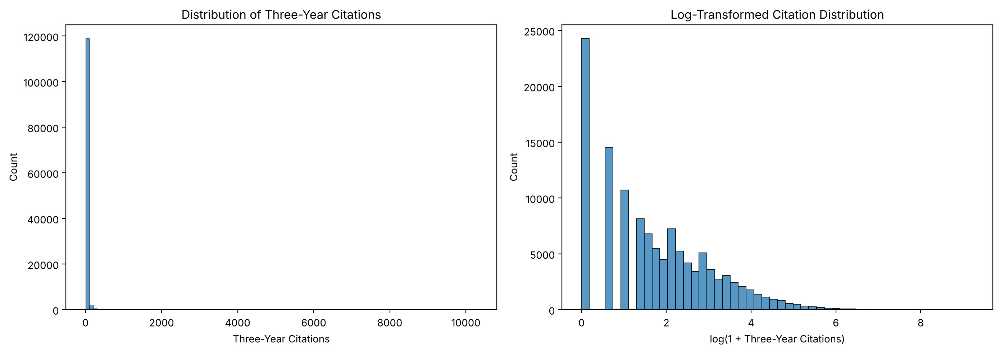

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=cleaned_papers_df, x="cites_3yr", bins=100, ax=axes[0])
axes[0].set_title("Distribution of Three-Year Citations")
axes[0].set_xlabel("Three-Year Citations")

sns.histplot(x=np.log1p(cleaned_papers_df["cites_3yr"]), bins=50, ax=axes[1])
axes[1].set_title("Log-Transformed Citation Distribution")
axes[1].set_xlabel("log(1 + Three-Year Citations)")

plt.tight_layout()
plt.show()

In the original plot (left), we observe that the citation is heavily **right-skewed**. A vast majority of papers receive zero or very few citations, creating a massive spike at the far left, while only a handful of outlier papers receive thousands of citations.

Because of this extreme skew, we want to **log-transform** the target variable, which shrinks those extreme outliers (without breaking the overall trend) to make the underlying distribution much easier to analyze and model.

## 3.2. Feature Outliers

Similar to analyzing the target variable, we will first inspect the numerical features' overall statistics and plot their their distributions.

In [39]:
# Exclude the binary features
binary_cols = ['has_code', 'has_company_author']

cleaned_papers_df[numerical_cols].drop(binary_cols, axis=1).describe().T

,count,mean,std,min,25%,50%,75%,max
publication_year,122097.0,2019.141797,0.803650,2018.0,2018.0,2019.0,2020.0,2020.0
institutions_distinct_count,122097.0,1.730608,1.648075,0.0,1.0,1.0,2.0,92.0
countries_distinct_count,122097.0,1.150602,0.855170,0.0,1.0,1.0,2.0,29.0
referenced_works_count,122097.0,30.043203,26.839846,0.0,14.0,26.0,40.0,966.0
locations_count,122097.0,3.462042,1.468013,1.0,2.0,3.0,4.0,28.0
num_repositories,122097.0,0.441911,2.770065,0.0,0.0,0.0,0.0,534.0
publication_month,122097.0,6.205894,3.622174,1.0,3.0,6.0,10.0,12.0
submission_month,122097.0,6.659852,3.359741,1.0,4.0,7.0,10.0,12.0
pub_after_arxiv_days,122097.0,94.883109,213.069370,0.0,0.0,0.0,103.0,9121.0
arxiv_after_pub_days,122097.0,35.924961,157.009584,0.0,0.0,1.0,1.0,2859.0


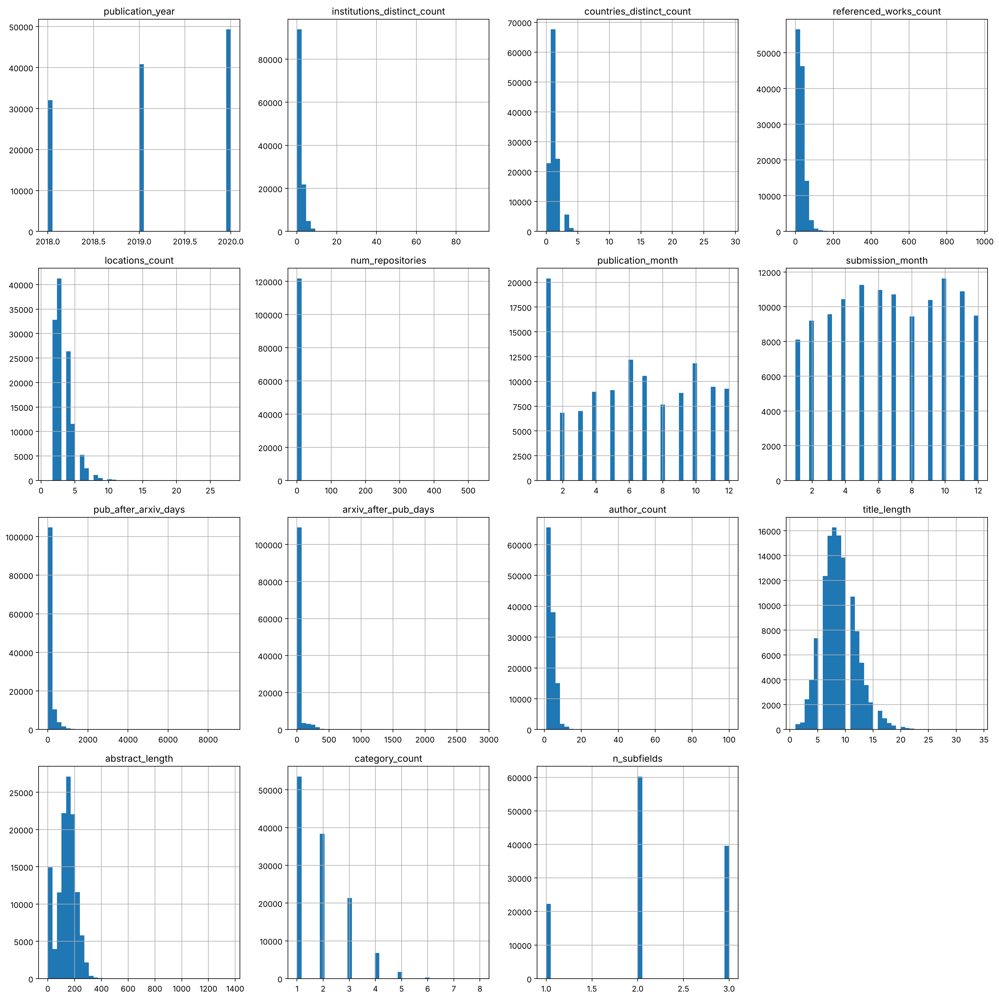

In [40]:
# Plot histograms
cleaned_papers_df[numerical_cols].drop(binary_cols, axis=1).hist(bins=40,figsize=(18, 18))
plt.tight_layout()
plt.show()

The above plots reveal that several features are right-skewed, which can be resolved by log-transforming them (similar to `cites_3yr`) to reduce the effects of extreme outliers.

We will then use the **Interquartile Range** (IQR) to detect and count the outliers in each of the numerical features.

In [41]:
outlier_results = []
include_cols = [c for c in numerical_cols if c not in binary_cols]

for col in include_cols:
    q1 = cleaned_papers_df[col].quantile(0.25)
    q3 = cleaned_papers_df[col].quantile(0.75)
    iqr = q3 - q1

    # Values that are below lower_bound or above upper_bound are outliers
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = cleaned_papers_df[
        (cleaned_papers_df[col] < lower_bound) |
        (cleaned_papers_df[col] > upper_bound)
    ]

    outlier_results.append({"Feature": col,
                            "Outlier Count": len(outliers),
                            "Outlier Percentage": len(outliers) / len(cleaned_papers_df) * 100,
                            "Lower Bound": lower_bound,
                            "Upper Bound": upper_bound})

outlier_df = pd.DataFrame(outlier_results)
outlier_df.sort_values("Outlier Percentage", ascending=False)

,Feature,Outlier Count,Outlier Percentage,Lower Bound,Upper Bound
5,num_repositories,28424,23.279851,0.0,0.0
9,arxiv_after_pub_days,18069,14.798889,-1.5,2.5
8,pub_after_arxiv_days,15226,12.470413,-154.5,257.5
1,institutions_distinct_count,13425,10.995356,-0.5,3.5
13,category_count,8889,7.280277,-0.5,3.5
3,referenced_works_count,3613,2.959123,-25.0,79.0
4,locations_count,2266,1.855901,-1.0,7.0
10,author_count,2249,1.841978,-2.5,9.5
2,countries_distinct_count,1598,1.308795,-0.5,3.5
11,title_length,1392,1.140077,1.0,17.0


We observe that `num_repositories`, `arxiv_after_pub_days`, `pub_after_arxiv_days`, and `institutions_distinct_count` account for higher outlier percentages. Additionally, `num_repositories` indicates that at least 75% of the research papers contains no repository (upper and lower IQR bounds), so the above process flagged any non-zero value as outliers. This information supports the decision to drop these features in Part `3.3.`. As mentioned above, we will log-transform the other outliers in the less affected features that were not dropped.

## 3.3. Correlation Matrix

We will use a **correlation matrix** to identify features that are highly correlated with each other and decide which columns to be dropped from our models. Because the data we collected are skewed and contain outliers (analyzed in parts `3.1.` and `3.2.`), we will use **Spearman**'s $\rho$ to measure the correlations between the features (and target) since this correlation type is a **non-parametric** test that can capture **non-linear** relationships.

In [42]:
correlation_matrix = cleaned_papers_df.corr(method='spearman', numeric_only=True)

# Plot heatmap of correlation matrix
fig = go.Figure(data=go.Heatmap(
   z=correlation_matrix,
   x=correlation_matrix.columns,
   y=correlation_matrix.index,
   colorscale='RdBu_r',
   text=correlation_matrix.round(2),
   texttemplate='%{text}',
   textfont={"size": 10},
   hoverongaps=False,
   zmin=-1
))

fig.update_layout(
   width=1100,
   height=1100,
   title='Correlation Matrix Heatmap',
   xaxis_title='',
   yaxis_title='',
   yaxis=dict(autorange='reversed')
)

While Random Forest and Gradient Boosting can handle multicollinearity, redundant features add no information, destabilize linear coefficients, and split importance across tree features. Thus, we will remove features that highly correlated with each other, specifically with a correlation value of at least $|\rho| = 0.80$.  Some of the notable correlated pairs include:

1. `num_repositories` ↔ `has_code` $(\rho \approx 0.99)$:
   - This near-perfect correlation occurs because a paper with code repository links will always register as having `has_code = 1`, whereas papers without open repositories register as `0`.
2. `pub_after_arxiv_days` ↔ `arxiv_after_pub_days` $(\rho \approx -0.88)$:
   - These are mutually exclusive representations of the time gap. If a paper is published on arXiv first, the delay to official publication is positive while the post-print delay is 0, and vice versa.
3. `institutions_distinct_count` ↔ `countries_distinct_count` $(\rho \approx 0.83)$:
   - Papers authored by researchers from a larger number of unique institutions naturally span across more countries, as institutional diversity highly correlates with international collaboration.
4. `pub_after_arxiv_days` ↔ `locations_count` $(\rho \approx 0.50)$:
   - A longer preprint-to-publication window allows more time for the work to be indexed, distributed, or archived in various database hosting locations.
5. `publication_month` ↔ `submission_month` $(\rho \approx 0.47)$:
   - Papers are often officially published shortly after their initial preprint submission, meaning the submission month moderately dictates the eventual publication month.

For the above correlated pairs that **exceed** $|\rho| = 0.80$, we will remove one feature from each during model training. These include:

- `institutions_distinct_count`: Due to the high outlier percentage computed in Part `3.2.`
- `num_repositories`: Due to being zero-inflated and having a high outlier percentage computed in Part `3.2.`
- `pub_after_arxiv_days`: Due to being correlated with `locations_count` $(\rho \approx 0.50)$

**Note**: Outliers can skew the model weights, so we drop features with more outliers to reduce the noise and allow less aggressive preprocessing (e.g., transformation, clipping) to resolve the issue.

## 3.4. Research Subfield Impact on Citation Count

In this sub-section, we will analyze which research **subfields** are the most common among the computer science research papers published in the arXiv archive in the OpenAlex API.

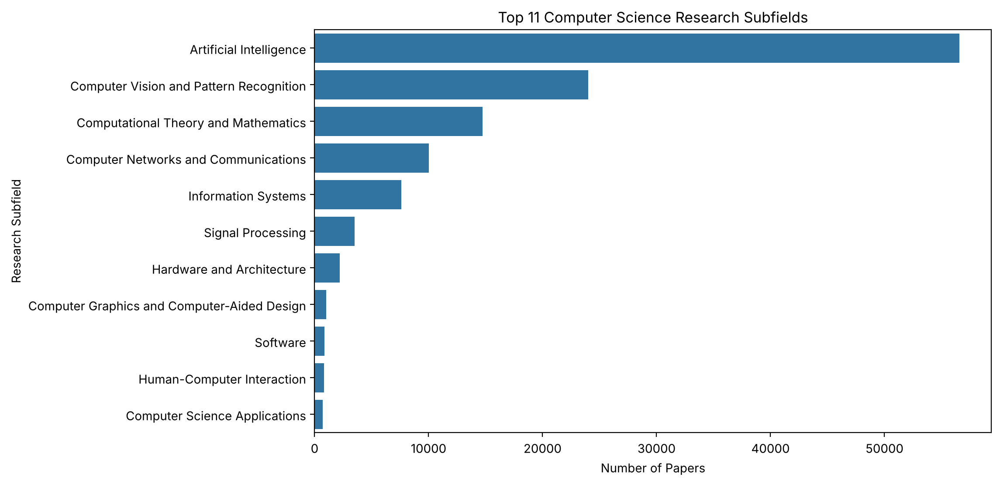

In [43]:
# Count the number of papers per subfield
top_subfields = cleaned_papers_df["primary_subfield"].value_counts().head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_subfields.values, y=top_subfields.index)
plt.title("Top 11 Computer Science Research Subfields")
plt.xlabel("Number of Papers")
plt.ylabel("Research Subfield")
plt.show()

We can see that **Artificial Intelligence** accounts for almost half (~47%) of the total published computer science papers in the OpenAlex arXiv archive. This makes sense since the **Transformer** architecture was published in the late 2017, which triggered an explosion of research about AI in 2018-2020. This significant breakthrough incentivized big tech giants (Google, Meta, OpenAI) to aggressively ramped up their AI reserach divisions during this period, which led to landmark models like BERT and the GPT series that revolutionized NLP.

**Computer Vision and Pattern** came second, accounting for about 20% of the computer science research. This subfield is also popular due to the emergence of **AlexNet**, a Convolutional Neural Network that crushed the competition in the Imagenet visual recognition challenge in 2012. This landmark event proved that deep neural networks could solve complex real-world problems, drawing massive attention and funding to the field.

Then, we will analyze which research areas have higher typical citation counts. From `3.1.`, we know that citation counts are highly **skewed**, where highly cited papers can substantially increase the mean. Hence, we will use the **median** to measure the citation counts of each subfield.

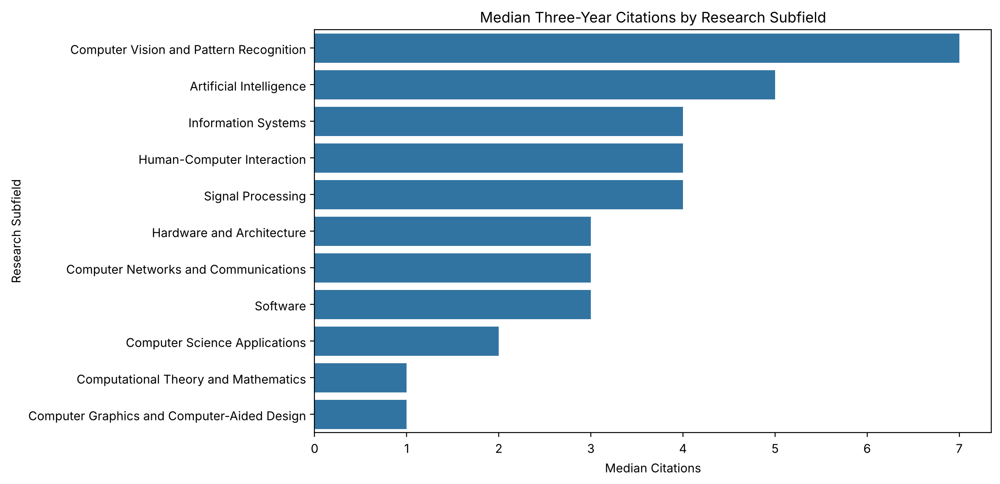

In [44]:
# Group all papers by their primary subfield and
# the median number of citations per subfield
subfield_stats = cleaned_papers_df.groupby("primary_subfield").agg(median_citations=("cites_3yr", "median"))

# Rank the subfields by the median number of citations
top_subfields_by_count = cleaned_papers_df["primary_subfield"].value_counts().head(15).index
plot_data = (subfield_stats.loc[top_subfields_by_count]
             .sort_values("median_citations", ascending=False).reset_index())

plt.figure(figsize=(10, 6))
sns.barplot(data=plot_data, x="median_citations", y="primary_subfield")
plt.title("Median Three-Year Citations by Research Subfield")
plt.xlabel("Median Citations")
plt.ylabel("Research Subfield")
plt.show()

Despite AI having the most research papers, this subfield has fewer citations than **Computer Vision and Pattern Recognition**. Because AI is a massive, accessible field, it suffers from a flood of low-impact or highly niche publications. Since it is a broad field, AI includes not just the cutting-edge deep learning, but also older, less active subfields like expert systems and theoretical search algorithms. The large volume of AI papers that received zero or one citation dragged down the median.

On the other hand, due to the recent breakthrough of the **Transformer** architecture, computer vision (CV) became the standard tools across other disciplines. Popular architectural innovations like ResNet or attention mechanisms applied to images are frequently cited not just by other CV researchers, but also by researchers in robotics, medical imaging, and general machine learning, giving CV papers a broader citation audience.

## 3.5. Research Collaboration Impact on Citation Count

We will analyze the effects of research collaboration on the number of citations a paper receives. Collaboration includes the number of authors contributed to the research (`author_count`) and the number of other works referenced in the paper (`referenced_works_counts`).

In [45]:
# Create a copy of the dataframe specifically for plotting
plot_df = cleaned_papers_df.copy()
plot_df["log_citations"] = np.log1p(plot_df["cites_3yr"])

# Group the authors into categorical bins based on the team size
cut_series = pd.cut(cleaned_papers_df['author_count'],
                    bins=[-np.inf, 1, 3, 5, 10, np.inf],
                    labels=["1", "2–3", "4–5", "6–10", "11+"])

# Calculate size of each group
counts_by_group = cut_series.value_counts()
label_map_authors = {group: f"{group} (n={counts_by_group[group]:,})" for group in counts_by_group.index}
category_order_authors = [label_map_authors[g] for g in ["1", "2–3", "4–5", "6–10", "11+"]]

plot_df['author_group'] = cut_series.map(label_map_authors)

# Create a box plot of the bins, sorted in ascending order
fig = px.box(plot_df, x="author_group", y="log_citations",
             title="Research Team Size and Citation Impact",
             category_orders={"author_group": category_order_authors},
             labels={"author_group": "Number of Authors",
                     "log_citations": "log(1 + Three-Year Citations)"})
fig.update_layout(template="plotly_white", xaxis_tickangle=-30)
fig.show()

We observed that a paper involving increasingly more authors is likely to receive increasingly higher statistical citation counts (e.g., median, spread, and max). This is because larger research teams can have access to broader expertise and collaboration networks. They may also have more opportunities to disseminate their work, allowing a paper to gain more exposure than otherwise smaller groups. Note that a majority of papers involved 2-5 authors, and a very small amount of researches involved more than 11 authors.

However, this analysis only identifies an association, not a causal relationship. That is, having more authors doesn't necessarily leads to more citations since highly collaborative research may also be concentrated in certain subfields that naturally receive more citations (shown in Part `3.4.`).

We will now analyze the extent to which a paper builds upon existing research associated with its subsequent citation impact.

In [46]:
# Divide the papers into 10 bins of equal size, each represents a different
# range of the number of referenced works involved in a paper
qcut_series = pd.qcut(plot_df["referenced_works_count"], q=10, duplicates="drop")

# Calculate size of each bin
counts_by_bin = qcut_series.value_counts()

# Helper to format interval
# Example: (11.0, 17.0] -> "12–17 (n=13,598)"
def format_interval(interval):
    left = int(np.floor(interval.left + 1))
    right = int(interval.right)
    n_samples = counts_by_bin[interval]
    if left >= right:
        return f"{right} (n={n_samples:,})"
    return f"{left}–{right} (n={n_samples:,})"

# Apply helper and build an ordered category mapping
unique_intervals = sorted(qcut_series.unique(), key=lambda x: x.left)
label_map = {interval: format_interval(interval) for interval in unique_intervals}
category_order = [label_map[interval] for interval in unique_intervals]

plot_df["reference_group"] = qcut_series.map(label_map)

fig = px.box(plot_df, x="reference_group", y="log_citations",
             title="Citation Impact by Number of Referenced Works",
             category_orders={"reference_group": category_order},
             labels={"reference_group": "Number of Referenced Works",
                     "log_citations": "log(1 + Three-Year Citations)"})
fig.update_layout(template="plotly_white", xaxis_tickangle=-30)
fig.show()

We observe that papers with very few references (e.g., 0–3) typically have lower median citations and tighter distributions. Conversely, papers that cite heavily (e.g., 57–966 references) have higher median citation counts. This trend likely exists because comprehensive papers, thorough reviews, and highly detailed studies require larger bibliographies and naturally become valuable hubs or reference points in their respective fields. However, a higher reference count does not guarantee more citations. The baseline citation density and bibliography expectations vary greatly across different scientific subfields (`3.4.`).

## 3.6. Temporal Trends

Academic submissions and publications are highly cyclical, often experiencing massive spikes around the submission deadlines of major prestigious conferences (e.g., CVPR, ICCV, NeurIPS, ICML). In this section, we analyze the distribution of papers across different months of the year for both their initial arXiv submission and their formal publication.

In [47]:
# Calculate the count of papers per month for both submissions and publications
sub_counts = cleaned_papers_df['submission_month'].value_counts().sort_index().reset_index()
sub_counts.columns = ['Month', 'Count']
sub_counts['Type'] = 'arXiv Submission'

pub_counts = cleaned_papers_df['publication_month'].value_counts().sort_index().reset_index()
pub_counts.columns = ['Month', 'Count']
pub_counts['Type'] = 'Official Publication'

# Combine into a single DataFrame for visualization
temporal_df = pd.concat([sub_counts, pub_counts], axis=0)

# Map numerical months to English abbreviations
month_names = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
               7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}
temporal_df['Month_Name'] = temporal_df['Month'].map(month_names)

# Generate a line chart comparing the trends
fig = px.line(temporal_df, x='Month_Name', y='Count', color='Type', markers=True,
              title='Monthly Seasonality: arXiv Submissions vs. Official Publications',
              labels={'Month_Name': 'Month', 'Count': 'Number of Papers'})

fig.update_layout(template='plotly_white',
                  xaxis=dict(categoryorder='array', categoryarray=list(month_names.values())),
                  hovermode='x unified')
fig.show()

We observe that the **arXiv Submission** line is  smoother month-to-month, maintaining a steady baseline between ~8,000 and ~12,000 submissions, indicating that preprint posting remains relatively stable year-round with minor deadline-driven bumps. Conversely, the **Official Publication** line is far more volatile. It exhibits a massive, artificial spike in **January** (exceeding 20,000 papers), which commonly happens in bibliographic databases like OpenAlex because papers with incomplete publication dates default to January 1st, alongside other volatile mid-year conference publishing spikes (e.g., June and October).

## 3.7. Industry, Venue, and Publishing Month

We will now analyze the relationships between some of the remaining engineered features (`has_company_author`, `venue_type`, and `publication_month`) and the target (`cites_3yr`).

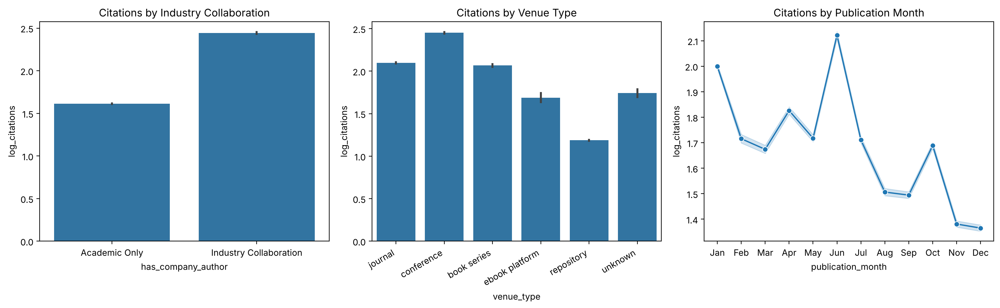

In [48]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))

# Industry vs non-Industry citations
sns.barplot(data=plot_df, x="has_company_author", y="log_citations", errorbar="se", ax=ax[0])
ax[0].set_title("Citations by Industry Collaboration")
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(["Academic Only", "Industry Collaboration"])

# Venue Type impact on citations
sns.barplot(data=plot_df, x="venue_type", y="log_citations", errorbar="se", ax=ax[1])
ax[1].set_title("Citations by Venue Type")
ax[1].set_xticks(range(len(plot_df["venue_type"].unique())))
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=30, ha="right")

# Monthly seasonality citation trajectory
sns.lineplot(data=plot_df, x="publication_month", y="log_citations", errorbar="se", marker="o", ax=ax[2])
ax[2].set_title("Citations by Publication Month")
ax[2].set_xticks(range(1, 13))
ax[2].set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])

plt.tight_layout()
plt.show()

We observe the following from analyzing how these engineered features relate to the three-year citation impact:

1. **Industry Collaboration (`has_company_author`)**:
   * Papers with at least one author affiliated with a company or corporate research lab receive significantly higher average citation rates compared to those written exclusively by academic researchers. This gap suggests that industry partnerships often bring substantial resources, high-performance computing capabilities, practical real-world applications, and extensive marketing/PR reach, driving higher academic visibility and engagement.

2. **Venue Type (`venue_type`)**:
   * Publishing venues exhibit dramatic differences in baseline citation volume. Journals and established conference proceedings yield substantially higher citations on average than repository preprints alone. This emphasizes that peer-reviewed certification, archival quality, and official metadata inclusion still play crucial roles in a paper's community adoption, even in preprint-heavy domains.

3. **Publication Month (`publication_month`)**:
   * Citations follow a clear cyclical trend depending on the month of the year a paper is published. Papers formally published early in the calendar year (especially January and February) tend to accumulate more citations over a rolling three-year window than those published in late autumn or winter. This likely reflects a simple "exposure duration" advantage: papers published in January have up to 11 additional months to circulate, build momentum, and accumulate citations compared to papers released in December of the same catalog year. Note that the spikes in January, June, and October are similar to the pattern in `3.6.`.

# Part 4: Feature Sets and Hypothesis Testing

## 4.1. Setup

In [49]:
# Extra libraries for Parts 4-5 (LightGBM is preinstalled on Colab)
from sklearn.linear_model import Ridge
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import KFold, GridSearchCV, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr, loguniform, randint, uniform
import lightgbm as lgb

SEED = 5450          # global random seed
N_PERM = 10_000      # permutations per hypothesis test (proposal: 10,000)
N_BOOT = 2_000       # paired-bootstrap resamples on the test set
N_ITER = 20          # random-search candidates for LightGBM (5-fold CV each)

## 4.2. Extra Features for the Extended Set

Part 2 dropped `comments` and `doi` before we built the extended (ablation) features from the proposal. We rebuild them here from the raw `papers_df`, aligned on the index of `cleaned_papers_df`:

- `venue_mention`: the arXiv comments say the paper was accepted at or appears in a venue (e.g. "accepted at", "to appear in", "camera ready", "CVPR 2019").
- `page_count`: page count from the comments; we keep missing values, so LightGBM can use them, and add a `has_page_count` flag. Ridge fills in the training median.
- `has_journal_doi`: the OpenAlex DOI is a publisher DOI, not an arXiv DataCite DOI (`10.48550/arXiv.*`). Since 2022 every arXiv paper has a DataCite DOI, so "has a DOI" alone would carry almost no signal.

All of these describe the **current** record, so they may have been added after posting. They stay in the extended set only.

In [50]:
model_df = cleaned_papers_df.copy()
raw = papers_df.loc[model_df.index]

# Target: log(1 + cites_3yr)
model_df["y"] = np.log1p(model_df["cites_3yr"])

# Venue mentioned in the arXiv comments
comments_raw = raw["comments"].fillna("")
venue_pat = (r"\b(?:accepted|to appear|appear(?:s|ed)? in|published in|camera[- ]ready|"
             r"proceedings of|in proc\.?)\b"
             r"|\b(?:cvpr|iccv|eccv|neurips|nips|icml|iclr|aaai|ijcai|acl|emnlp|naacl|kdd|"
             r"sigir|icra|iros|miccai|interspeech|icassp)\s*'?\d{2,4}\b")
model_df["venue_mention"] = comments_raw.str.contains(venue_pat, case=False, regex=True).astype(int)

# Page count from the comments (values above 500 are treated as parse errors)
model_df["page_count"] = pd.to_numeric(
    comments_raw.str.extract(r"(\d+)\s*pages?", flags=re.I)[0], errors="coerce")
model_df.loc[model_df["page_count"] > 500, "page_count"] = np.nan
model_df["has_page_count"] = model_df["page_count"].notna().astype(int)

# Publisher (non-arXiv) DOI
doi = raw["doi"].fillna("").str.lower()
model_df["has_journal_doi"] = ((doi != "") & ~doi.str.contains(r"10\.48550|arxiv")).astype(int)

model_df[["venue_mention", "has_page_count", "has_journal_doi", "has_code"]].mean().round(3)

venue_mention      0.248
has_page_count     0.288
has_journal_doi    0.535
has_code           0.233
dtype: float64

## 4.3. Sanity Check on the Date Fields

`publication_date` comes from OpenAlex and is often the journal or conference date, or a default of 1 January. `submission_month` comes from the first arXiv version. Before relying on either, we check how often the OpenAlex date is a 1 January default, how often the two dates are within a day of each other, and how often the two years disagree. Year disagreements matter because the year sets both the 3-year citation window and the train/test split.

In [51]:
v1 = pd.to_datetime(raw["versions"].apply(get_first_submission), errors="coerce", utc=True)
v1 = v1.dt.tz_localize(None).dt.normalize()
pub = pd.to_datetime(raw["publication_date"], errors="coerce")
gap_days = (pub - v1).dt.days

date_check = pd.Series({
    "OpenAlex date is Jan 1":              (pub.dt.strftime("%m-%d") == "01-01").mean(),
    "|OpenAlex - arXiv v1| <= 1 day":       (gap_days.abs() <= 1).mean(),
    "OpenAlex date > 30 days before arXiv": (gap_days < -30).mean(),
    "OpenAlex date > 30 days after arXiv":  (gap_days > 30).mean(),
    "OpenAlex year != arXiv v1 year":       (pub.dt.year != v1.dt.year).mean(),
}).round(3)
date_check

OpenAlex date is Jan 1                  0.122
|OpenAlex - arXiv v1| <= 1 day          0.479
OpenAlex date > 30 days before arXiv    0.122
OpenAlex date > 30 days after arXiv     0.341
OpenAlex year != arXiv v1 year          0.232
dtype: float64

**How to read this.** If most negative gaps are only one day, they come from time zones and arXiv's announcement schedule, not from post-prints. The share of papers posted to arXiv well after publication is the "> 30 days before arXiv" row. The `arxiv_after_pub_days` feature (median 1 day in Part 3.2) is mostly this noise, so we keep it out of the main set. The year-disagreement row shows how many papers have a citation window that starts in a different year from their arXiv posting. We keep the proposal's definition for comparability and flag this as a limitation.

## 4.4. Feature Sets

Following the proposal, the **main** set uses only information available when a paper is first posted. The **extended** set adds fields that describe the paper's *current* record and may have changed after posting. Some features are left out entirely:

| Excluded | Reason |
|---|---|
| `num_repositories` | Papers with Code counts third-party reimplementations, which pile up *because* a paper became popular (reverse causality). |
| `publication_year` | The 2020 test year never appears in training, so trees cannot use it and Ridge would extrapolate it. |
| `institutions_distinct_count` | ρ≈0.83 with `countries_distinct_count` (Part 3.3). |
| `is_oa`, `any_repository_has_fulltext`, `language` | Constant or near-constant (every arXiv paper is open access). |

`has_code` was in the proposal's main set. Part 2 moved it to the leaky set because Papers with Code links can be added at any time after posting. We follow Part 2 and test it in the extended set.

In [52]:
TARGET = "y"
SUBFIELD = ["primary_subfield"]

MAIN_NUM = ["author_count", "countries_distinct_count", "has_company_author",
            "referenced_works_count", "title_length", "abstract_length",
            "category_count", "n_subfields", "submission_month", "publication_month"]
MAIN_CAT = ["primary_subfield", "primary_category", "first_author_country", "license"]

EXT_NUM = ["has_code", "locations_count", "has_journal_doi", "venue_mention",
           "page_count", "has_page_count", "pub_after_arxiv_days", "arxiv_after_pub_days"]
EXT_CAT = ["venue_type", "type", "oa_status"]

# Right-skewed counts get log1p for Ridge (Part 3.2)
SKEWED = {"author_count", "countries_distinct_count", "referenced_works_count",
          "abstract_length", "category_count", "locations_count", "page_count",
          "pub_after_arxiv_days", "arxiv_after_pub_days"}
MONTHS = {"submission_month", "publication_month"}   # one-hot for Ridge

FEATURE_SETS = {
    "subfield": ([], SUBFIELD),
    "main":     (MAIN_NUM, MAIN_CAT),
    "extended": (MAIN_NUM + EXT_NUM, MAIN_CAT + EXT_CAT),
}

## 4.5. Permutation Tests

We test three beliefs about early citations. Each test is one-sided (H₁: group A has the higher mean log(1 + cites_3yr)):

1. **Code:** A = `has_code = 1`, B = `has_code = 0`.
2. **Team size:** A = top quartile of `author_count`, B = bottom quartile. `author_count` has many ties, so we use A = authors ≥ Q3 and B = authors ≤ Q1 and report the group sizes.
3. **Venue mention:** A = `venue_mention = 1`, B = `venue_mention = 0`.

**Procedure.** We shuffle the outcome *within* each `primary_subfield × publication_year` stratum, which is the same as shuffling the group labels within strata, so subfield and age stay fixed. The test runs 10,000 times, and p = (1 + #{null ≥ observed}) / (1 + 10,000).

Because the shuffle is restricted to strata, the null distribution is **not centred at 0**. Its mean is the difference that subfield and year composition alone would produce. *Observed − null mean* is therefore a confounding-adjusted effect size. With roughly 120,000 papers, even tiny effects will be significant, so we report that adjusted effect alongside p.

In [53]:
def stratified_perm_test(y, group_a, group_b, strata, n_perm=N_PERM, seed=SEED, chunk=200):
    # One-sided permutation test of mean(y[A]) - mean(y[B]), shuffling y within strata.
    rng = np.random.default_rng(seed)
    y = np.asarray(y, dtype=float)
    a = np.asarray(group_a, dtype=bool)
    b = np.asarray(group_b, dtype=bool)
    codes = pd.factorize(pd.Series(strata).astype(str))[0]
    observed = y[a].mean() - y[b].mean()

    sum_a = np.zeros(n_perm)
    sum_b = np.zeros(n_perm)
    for s in np.unique(codes):
        idx = np.flatnonzero(codes == s)
        wa, wb = a[idx].astype(float), b[idx].astype(float)
        if wa.sum() == 0 and wb.sum() == 0:
            continue
        ys = y[idx]
        for start in range(0, n_perm, chunk):
            m = min(chunk, n_perm - start)
            perm = rng.permuted(np.tile(ys, (m, 1)), axis=1)
            sum_a[start:start + m] += perm @ wa
            sum_b[start:start + m] += perm @ wb

    null = sum_a / a.sum() - sum_b / b.sum()
    p = (1 + np.sum(null >= observed)) / (1 + n_perm)
    return observed, null, p

In [54]:
strata = model_df["primary_subfield"].astype(str) + "|" + model_df["publication_year"].astype(str)
q1, q3 = model_df["author_count"].quantile([0.25, 0.75])

tests = {
    "has_code":       (model_df["has_code"] == 1, model_df["has_code"] == 0),
    f"authors >= {q3:g} vs <= {q1:g}":
                      (model_df["author_count"] >= q3, model_df["author_count"] <= q1),
    "venue_mention":  (model_df["venue_mention"] == 1, model_df["venue_mention"] == 0),
}

alpha, n_tests = 0.05, len(tests)
rows, nulls = [], {}
for name, (ga, gb) in tests.items():
    obs, null, p = stratified_perm_test(model_df[TARGET], ga, gb, strata)
    nulls[name] = (obs, null)
    rows.append({"test": name, "n_A": int(ga.sum()), "n_B": int(gb.sum()),
                 "observed diff": obs, "null mean": null.mean(),
                 "adjusted effect": obs - null.mean(), "p-value": p,
                 "reject @0.05": p < alpha,
                 f"reject @Bonferroni {alpha / n_tests:.4f}": p < alpha / n_tests})

hyp_results = pd.DataFrame(rows).set_index("test")
hyp_results.round(4)

,n_A,n_B,observed diff,null mean,adjusted effect,p-value,reject @0.05,reject @Bonferroni 0.0167
test,,,,,,,,
has_code,28424,93673,1.0427,0.1610,0.8816,0.0001,True,True
authors >= 5 vs <= 2,33270,35968,0.9747,0.1688,0.8059,0.0001,True,True
venue_mention,30270,91827,0.7343,0.1122,0.6221,0.0001,True,True


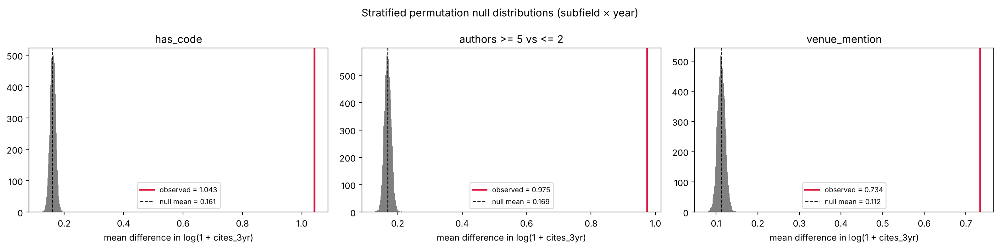

In [55]:
fig, axes = plt.subplots(1, n_tests, figsize=(16, 4))
for ax, (name, (obs, null)) in zip(axes, nulls.items()):
    ax.hist(null, bins=60, color="lightgray", edgecolor="gray")
    ax.axvline(obs, color="crimson", lw=2, label=f"observed = {obs:.3f}")
    ax.axvline(null.mean(), color="black", ls="--", lw=1, label=f"null mean = {null.mean():.3f}")
    ax.set_title(name)
    ax.set_xlabel("mean difference in log(1 + cites_3yr)")
    ax.legend(fontsize=8)
plt.suptitle("Stratified permutation null distributions (subfield × year)")
plt.tight_layout()
plt.show()

**Interpretation notes.**
- If the observed line sits far to the right of the whole null histogram, p hits its floor of 1/10,001 ≈ 1e-4. That only says the effect is not chance, so judge size by the *adjusted effect*. On the log scale, a difference of d means roughly a (e^d − 1)×100% change in (1 + citations).
- These are associations, not causal effects. `has_code` especially can be reverse-causal: popular papers attract reimplementations, and Papers with Code may link a repo long after posting. A cleaner version would count only repositories marked `is_official` or `mentioned_in_paper` in the Papers with Code links file.

# Part 5: Modeling

## 5.1. Temporal Split

We train on 2018–2019 and test on 2020. Preprocessing and baseline statistics are fitted on the training data only. Hyperparameters are tuned with 5-fold CV inside the training set.

The 2020 cohort can differ from 2018–2019 in ways no feature captures: its citation window (2020–2022) covers different years, and publishing patterns and OpenAlex coverage change over time. Any such shift appears as a **level bias** on the test set. We therefore report the mean prediction bias (mean of ŷ − y) next to RMSE and MAE. Spearman ρ, which ignores a constant shift, measures pure ranking ability.

In [56]:
train_mask = model_df["publication_year"].isin([2018, 2019])
test_mask = model_df["publication_year"] == 2020
train_df, test_df = model_df[train_mask].copy(), model_df[test_mask].copy()
y_train, y_test = train_df[TARGET].to_numpy(), test_df[TARGET].to_numpy()

print(f"Train: {len(train_df):,} papers (2018-2019) | Test: {len(test_df):,} papers (2020)")
print(f"Mean log target  train = {y_train.mean():.3f}  test = {y_test.mean():.3f}")

Train: 72,785 papers (2018-2019) | Test: 49,312 papers (2020)
Mean log target  train = 1.740  test = 1.703


## 5.2. Helpers

- `make_pipeline`: Ridge gets median imputation, log1p on skewed counts, standardisation, and one-hot months. LightGBM gets raw numbers (missing values allowed). Both one-hot encode categoricals and fold levels with fewer than 20 training papers into an "infrequent" bucket.
- `evaluate`: RMSE, MAE and Spearman on the log target, plus mean bias.

In [57]:
def make_pipeline(num_cols, cat_cols, model, linear):
    transformers = []
    if linear:
        month_cols = [c for c in num_cols if c in MONTHS]
        skew_cols = [c for c in num_cols if c in SKEWED]
        lin_cols = [c for c in num_cols if c not in SKEWED and c not in MONTHS]
        if skew_cols:
            transformers.append(("log", Pipeline([
                ("imp", SimpleImputer(strategy="median")),
                ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                ("sc", StandardScaler())]), skew_cols))
        if lin_cols:
            transformers.append(("num", Pipeline([
                ("imp", SimpleImputer(strategy="median")),
                ("sc", StandardScaler())]), lin_cols))
        cat_all = cat_cols + month_cols
    else:
        if num_cols:
            transformers.append(("num", "passthrough", num_cols))
        cat_all = cat_cols
    if cat_all:
        transformers.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                  min_frequency=20), cat_all))
    return Pipeline([("prep", ColumnTransformer(transformers)), ("model", model)])


def evaluate(y_true, y_pred):
    y_pred = np.asarray(y_pred, dtype=float)
    rho = np.nan if np.ptp(y_pred) == 0 else spearmanr(y_true, y_pred).correlation
    return {"RMSE": root_mean_squared_error(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "Spearman": rho,
            "Bias": np.mean(y_pred - y_true)}


cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
results, preds, fitted = {}, {}, {}

## 5.3. Baselines (E1)

- **B1 Global Median:** predicts the training median of log(1 + cites_3yr) for every paper.
- **B2 Subfield Median:** predicts the training median within each `primary_subfield`, falling back to the global median for subfields never seen in training.

In [58]:
global_median = np.median(y_train)
sub_medians = train_df.groupby("primary_subfield")[TARGET].median()

preds["B1 Global Median"] = np.full(len(test_df), global_median)
preds["B2 Subfield Median"] = (test_df["primary_subfield"].map(sub_medians)
                               .fillna(global_median).to_numpy())

for name in ["B1 Global Median", "B2 Subfield Median"]:
    results[name] = {"Features": "None" if name.startswith("B1") else "Subfield",
                     **evaluate(y_test, preds[name])}
pd.DataFrame(results).T

,Features,RMSE,MAE,Spearman,Bias
B1 Global Median,None,1.322643,1.077471,NaN,-0.093657
B2 Subfield Median,Subfield,1.295531,1.051772,0.191716,-0.051615


## 5.4. Ridge Regression (M1, M2, M4)

We tune `alpha` over a log grid with 5-fold CV on the training set.

In [59]:
ridge_grid = {"model__alpha": np.logspace(-2, 3, 11)}
ridge_specs = {"M1 Ridge": "subfield", "M2 Ridge": "main", "M4 Ridge": "extended"}

for name, fs in ridge_specs.items():
    num_cols, cat_cols = FEATURE_SETS[fs]
    search = GridSearchCV(make_pipeline(num_cols, cat_cols, Ridge(), linear=True),
                          ridge_grid, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(train_df[num_cols + cat_cols], y_train)
    fitted[name] = search.best_estimator_
    preds[name] = search.predict(test_df[num_cols + cat_cols])
    results[name] = {"Features": fs, **evaluate(y_test, preds[name])}
    print(f"{name:10s} [{fs:8s}] best alpha = {search.best_params_['model__alpha']:.3g}  "
          f"CV RMSE = {-search.best_score_:.4f}")

M1 Ridge   [subfield] best alpha = 10  CV RMSE = 1.3192


M2 Ridge   [main    ] best alpha = 31.6  CV RMSE = 1.1519


M4 Ridge   [extended] best alpha = 10  CV RMSE = 1.0351


## 5.5. LightGBM (M3, M5)

We run a random search over `N_ITER` candidates with 5-fold CV on the main feature set. The best configuration is then reused for M5 and for the ablations, so differences come from the features rather than from the tuning.

In [60]:
lgb_space = {
    "model__n_estimators":      randint(200, 1200),
    "model__learning_rate":     loguniform(0.01, 0.1),
    "model__num_leaves":        randint(15, 128),
    "model__min_child_samples": randint(20, 200),
    "model__subsample":         uniform(0.6, 0.4),
    "model__colsample_bytree":  uniform(0.5, 0.5),
    "model__reg_lambda":        loguniform(1e-3, 10),
}
base_lgb = lgb.LGBMRegressor(subsample_freq=1, random_state=SEED, n_jobs=-1, verbose=-1)

num_cols, cat_cols = FEATURE_SETS["main"]
lgb_search = RandomizedSearchCV(make_pipeline(num_cols, cat_cols, base_lgb, linear=False),
                                lgb_space, n_iter=N_ITER, cv=cv, random_state=SEED,
                                scoring="neg_root_mean_squared_error", n_jobs=1)
lgb_search.fit(train_df[num_cols + cat_cols], y_train)
best_lgb_params = {k.replace("model__", ""): v for k, v in lgb_search.best_params_.items()}
print("Best LightGBM params:", {k: round(v, 4) if isinstance(v, float) else v
                                for k, v in best_lgb_params.items()})
print(f"CV RMSE = {-lgb_search.best_score_:.4f}")


def fit_lgb(num_cols, cat_cols, data=train_df, target=y_train):
    model = lgb.LGBMRegressor(subsample_freq=1, random_state=SEED, n_jobs=-1, verbose=-1,
                              **best_lgb_params)
    pipe = make_pipeline(num_cols, cat_cols, model, linear=False)
    return pipe.fit(data[num_cols + cat_cols], target)


for name, fs in {"M3 LightGBM": "main", "M5 LightGBM": "extended"}.items():
    num_cols, cat_cols = FEATURE_SETS[fs]
    fitted[name] = fit_lgb(num_cols, cat_cols)
    preds[name] = fitted[name].predict(test_df[num_cols + cat_cols])
    results[name] = {"Features": fs, **evaluate(y_test, preds[name])}

Best LightGBM params: {'colsample_bytree': np.float64(0.8766), 'learning_rate': np.float64(0.0158), 'min_child_samples': 23, 'n_estimators': 756, 'num_leaves': 82, 'reg_lambda': np.float64(0.0327), 'subsample': np.float64(0.6834)}
CV RMSE = 1.0625


## 5.6. Results on the 2020 Test Set (Table 3)

In [61]:
order = ["B1 Global Median", "B2 Subfield Median", "M1 Ridge", "M2 Ridge",
         "M3 LightGBM", "M4 Ridge", "M5 LightGBM"]
results_df = pd.DataFrame(results).T.loc[order]
results_df[["RMSE", "MAE", "Spearman", "Bias"]] = results_df[
    ["RMSE", "MAE", "Spearman", "Bias"]].astype(float).round(4)
results_df

,Features,RMSE,MAE,Spearman,Bias
B1 Global Median,None,1.3226,1.0775,NaN,-0.0937
B2 Subfield Median,Subfield,1.2955,1.0518,0.1917,-0.0516
M1 Ridge,subfield,1.2887,1.0559,0.1947,0.0543
M2 Ridge,main,1.1369,0.9139,0.5103,0.1696
M3 LightGBM,main,1.0563,0.8415,0.6018,0.1906
M4 Ridge,extended,1.0231,0.8132,0.6423,0.1759
M5 LightGBM,extended,0.9722,0.7695,0.6809,0.1878


## 5.7. Paired Bootstrap on Test Differences (E1, E2, E3, E5)

We resample test papers with replacement `N_BOOT` times and recompute each pair of models' RMSE and MAE on the same resample. A 95% CI for ΔRMSE = RMSE(reference) − RMSE(candidate) that sits entirely above 0 means the candidate is reliably better.

In [62]:
def paired_bootstrap(y, p_ref, p_new, n_boot=N_BOOT, seed=SEED, chunk=100):
    rng = np.random.default_rng(seed)
    se_ref, se_new = (y - p_ref) ** 2, (y - p_new) ** 2
    ae_ref, ae_new = np.abs(y - p_ref), np.abs(y - p_new)
    d_rmse, d_mae = [], []
    for start in range(0, n_boot, chunk):
        idx = rng.integers(0, len(y), size=(min(chunk, n_boot - start), len(y)))
        d_rmse.append(np.sqrt(se_ref[idx].mean(1)) - np.sqrt(se_new[idx].mean(1)))
        d_mae.append(ae_ref[idx].mean(1) - ae_new[idx].mean(1))
    return np.concatenate(d_rmse), np.concatenate(d_mae)


comparisons = [("E1", "B1 Global Median", "B2 Subfield Median"),
               ("E2", "M1 Ridge", "M2 Ridge"),
               ("E3", "M2 Ridge", "M3 LightGBM"),
               ("E5", "M2 Ridge", "M4 Ridge"),
               ("E5", "M3 LightGBM", "M5 LightGBM")]
rows = []
for exp, ref, new in comparisons:
    d_rmse, d_mae = paired_bootstrap(y_test, preds[ref], preds[new])
    lo, hi = np.percentile(d_rmse, [2.5, 97.5])
    rows.append({"Experiment": exp, "Reference": ref, "Candidate": new,
                 "ΔRMSE": d_rmse.mean(), "ΔRMSE 95% CI": f"[{lo:.4f}, {hi:.4f}]",
                 "ΔMAE": d_mae.mean(), "P(candidate not better)": np.mean(d_rmse <= 0)})
bootstrap_df = pd.DataFrame(rows)
bootstrap_df.round(4)

,Experiment,Reference,Candidate,ΔRMSE,ΔRMSE 95% CI,ΔMAE,P(candidate not better)
0,E1,B1 Global Median,B2 Subfield Median,0.0272,"[0.0238, 0.0304]",0.0258,0.0
1,E2,M1 Ridge,M2 Ridge,0.1518,"[0.1463, 0.1574]",0.1421,0.0
2,E3,M2 Ridge,M3 LightGBM,0.0806,"[0.0766, 0.0845]",0.0723,0.0
3,E5,M2 Ridge,M4 Ridge,0.1137,"[0.1089, 0.1183]",0.1005,0.0
4,E5,M3 LightGBM,M5 LightGBM,0.0840,"[0.0795, 0.0882]",0.0719,0.0


## 5.8. Group Ablation with LightGBM (E4)

We retrain M3, keeping the hyperparameters fixed, with one group of main features removed at a time. ΔRMSE and ΔMAE are the increase in test error versus the full M3. A larger value means the group matters more.

In [63]:
FEATURE_GROUPS = {
    "Team":       ["author_count", "countries_distinct_count", "has_company_author",
                   "first_author_country"],
    "References": ["referenced_works_count"],
    "Topic":      ["primary_subfield", "primary_category", "n_subfields", "category_count"],
    "Text length":["title_length", "abstract_length"],
    "Timing":     ["submission_month", "publication_month"],
    "License":    ["license"],
}
full = results["M3 LightGBM"]
rows = []
for group, cols in FEATURE_GROUPS.items():
    num_cols = [c for c in MAIN_NUM if c not in cols]
    cat_cols = [c for c in MAIN_CAT if c not in cols]
    pipe = fit_lgb(num_cols, cat_cols)
    m = evaluate(y_test, pipe.predict(test_df[num_cols + cat_cols]))
    rows.append({"Removed group": group, "RMSE": m["RMSE"],
                 "ΔRMSE": m["RMSE"] - full["RMSE"], "ΔMAE": m["MAE"] - full["MAE"],
                 "ΔSpearman": m["Spearman"] - full["Spearman"]})
ablation_df = pd.DataFrame(rows).sort_values("ΔRMSE", ascending=False).set_index("Removed group")
ablation_df.round(4)

,RMSE,ΔRMSE,ΔMAE,ΔSpearman
Removed group,,,,
Timing,1.1203,0.0640,0.0530,-0.0687
Team,1.0881,0.0318,0.0274,-0.0341
References,1.0858,0.0296,0.0263,-0.0351
Topic,1.0778,0.0215,0.0229,-0.0239
Text length,1.0602,0.0040,0.0032,-0.0029
License,1.0576,0.0014,0.0014,-0.0008


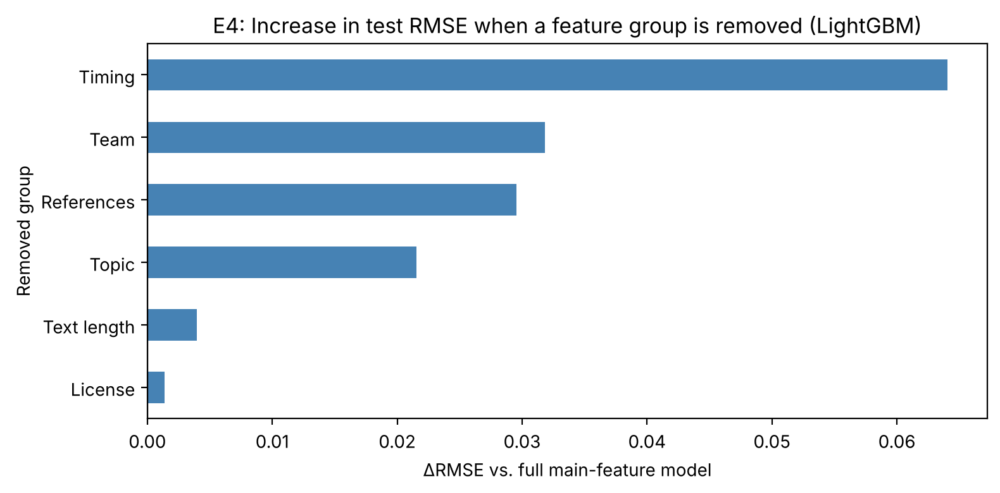

In [64]:
ax = ablation_df["ΔRMSE"].sort_values().plot.barh(figsize=(8, 4), color="steelblue")
ax.axvline(0, color="black", lw=0.8)
ax.set_title("E4: Increase in test RMSE when a feature group is removed (LightGBM)")
ax.set_xlabel("ΔRMSE vs. full main-feature model")
plt.tight_layout()
plt.show()

## 5.9. Permutation Importance and Ridge Coefficients

Permutation importance is the drop in test RMSE when one *raw* input column is shuffled. Because it works on raw columns, a one-hot categorical counts as a single feature. To keep run time down we use a random sample of 10,000 test papers and 5 repeats.

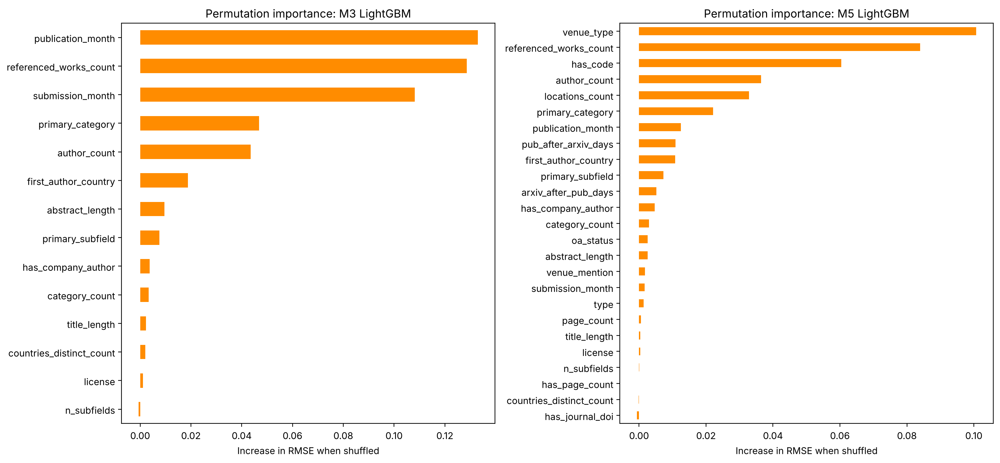

In [65]:
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(test_df), size=min(10_000, len(test_df)), replace=False)

imp_tables = {}
for name, fs in {"M3 LightGBM": "main", "M5 LightGBM": "extended"}.items():
    num_cols, cat_cols = FEATURE_SETS[fs]
    X_s = test_df[num_cols + cat_cols].iloc[sample_idx]
    pi = permutation_importance(fitted[name], X_s, y_test[sample_idx], n_repeats=5,
                                scoring="neg_root_mean_squared_error",
                                random_state=SEED, n_jobs=1)
    imp_tables[name] = pd.Series(pi.importances_mean, index=X_s.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, (name, imp) in zip(axes, imp_tables.items()):
    imp.plot.barh(ax=ax, color="darkorange")
    ax.set_title(f"Permutation importance: {name}")
    ax.set_xlabel("Increase in RMSE when shuffled")
plt.tight_layout()
plt.show()

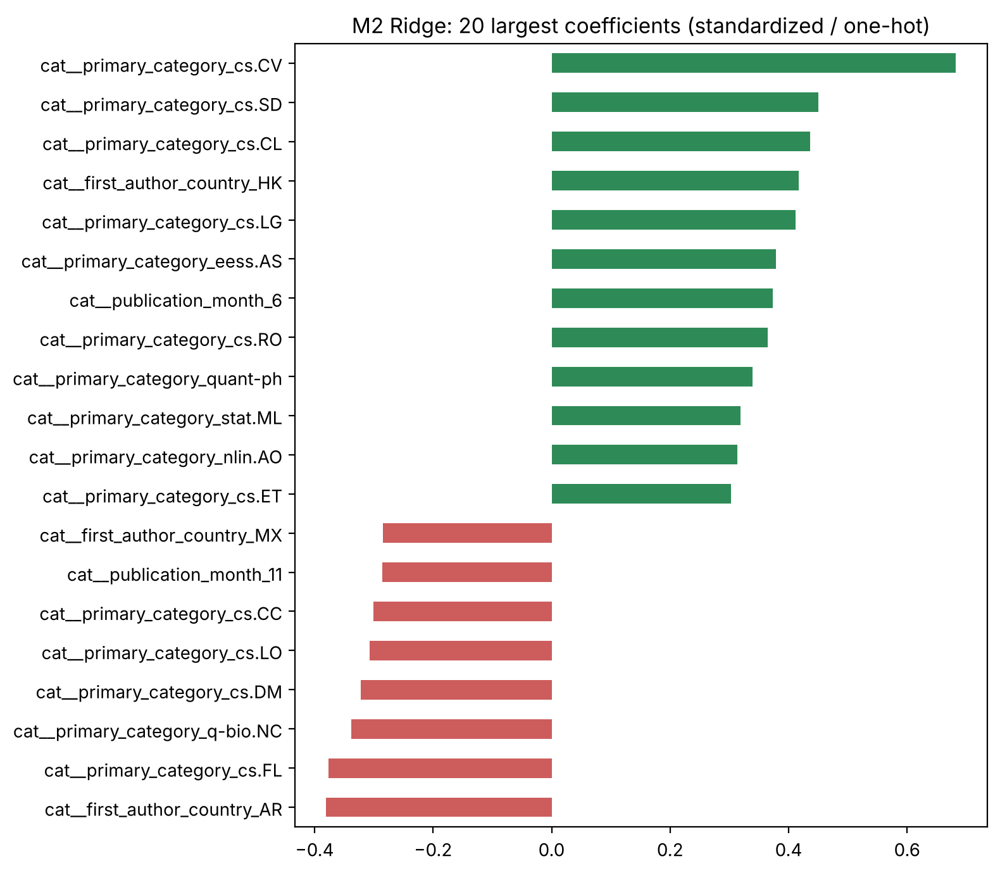

In [66]:
# Largest standardized Ridge coefficients (M2, main features)
ridge_m2 = fitted["M2 Ridge"]
coef = pd.Series(ridge_m2.named_steps["model"].coef_,
                 index=ridge_m2.named_steps["prep"].get_feature_names_out())
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).index).head(20)

ax = top_coef.sort_values().plot.barh(figsize=(8, 7),
                                      color=np.where(top_coef.sort_values() > 0, "seagreen", "indianred"))
ax.set_title("M2 Ridge: 20 largest coefficients (standardized / one-hot)")
plt.tight_layout()
plt.show()

## 5.10. Window Skew by Publication Month

A January paper gets almost three years of citations and a December paper just over two. We check whether `publication_month` absorbs this by plotting the mean residual (ŷ − y) of M3 by month on the test set. A flat line means the skew is handled. A trend means it is not.

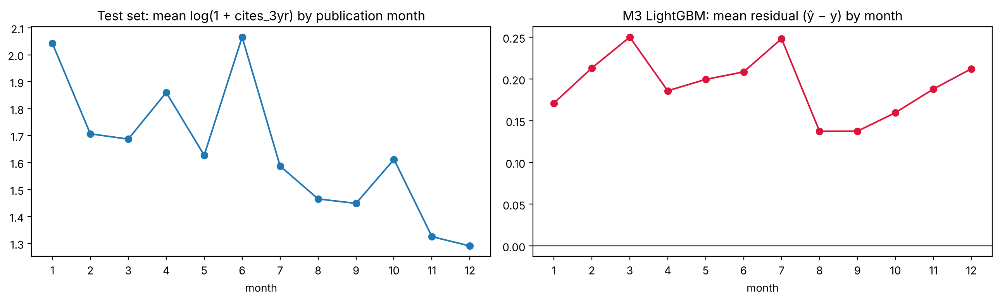

In [67]:
resid = pd.DataFrame({"month": test_df["publication_month"].to_numpy(),
                      "residual": preds["M3 LightGBM"] - y_test,
                      "y": y_test})
by_month = resid.groupby("month").agg(mean_y=("y", "mean"), mean_residual=("residual", "mean"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
by_month["mean_y"].plot(ax=ax[0], marker="o")
ax[0].set_title("Test set: mean log(1 + cites_3yr) by publication month")
by_month["mean_residual"].plot(ax=ax[1], marker="o", color="crimson")
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set_title("M3 LightGBM: mean residual (ŷ − y) by month")
for a in ax:
    a.set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

## 5.11. Optional Task: Top 10% in Subfield and Year

A paper's label is 1 if its `cites_3yr` is above the 90th percentile of its `primary_subfield × publication_year` cohort. The threshold uses only labels, never features, so computing it inside the 2020 test cohort does not leak. Cohort-relative labels also remove the year-level shift from 5.1. We report test AUROC for (a) ranking by M3's regression output, and (b) LightGBM classifiers on the main and extended sets.

In [68]:
cohort = model_df["primary_subfield"].astype(str) + "|" + model_df["publication_year"].astype(str)
thresh = model_df.groupby(cohort)["cites_3yr"].transform(lambda s: s.quantile(0.9))
model_df["top10"] = (model_df["cites_3yr"] > thresh).astype(int)
c_train, c_test = model_df.loc[train_mask, "top10"].to_numpy(), model_df.loc[test_mask, "top10"].to_numpy()
print(f"Positive rate  train = {c_train.mean():.3f}  test = {c_test.mean():.3f}")

auc_rows = {"M3 regression score (main)": roc_auc_score(c_test, preds["M3 LightGBM"])}
clf_params = {k: v for k, v in best_lgb_params.items()}
for fs in ["main", "extended"]:
    num_cols, cat_cols = FEATURE_SETS[fs]
    clf = make_pipeline(num_cols, cat_cols,
                        lgb.LGBMClassifier(subsample_freq=1, random_state=SEED, n_jobs=-1,
                                           verbose=-1, **clf_params), linear=False)
    clf.fit(train_df[num_cols + cat_cols], c_train)
    auc_rows[f"LightGBM classifier ({fs})"] = roc_auc_score(
        c_test, clf.predict_proba(test_df[num_cols + cat_cols])[:, 1])
pd.Series(auc_rows, name="Test AUROC").round(4).to_frame()

Positive rate  train = 0.098  test = 0.098


,Test AUROC
M3 regression score (main),0.7999
LightGBM classifier (main),0.8181
LightGBM classifier (extended),0.8634


# Part 6: Conclusion

All numbers below are from the 2020 test set (49,312 papers). The model was trained on 72,785 papers from 2018–2019.

**Hypothesis tests (4.5).** All three null hypotheses are rejected, including at the Bonferroni level of 0.0167; p sits at its floor of 1/10,001. The stratified null means are small (0.11–0.17), so subfield and year composition explain only a small part of each raw gap. Adjusted effects on log(1 + cites_3yr):

| Group comparison | Adjusted effect | ≈ ratio of (1 + citations) |
|---|---|---|
| has_code vs. no code | 0.88 | 2.4× |
| ≥ 5 authors vs. ≤ 2 authors | 0.81 | 2.2× |
| venue mentioned in comments vs. not | 0.62 | 1.9× |

These are associations. `has_code` in particular is partly reverse-causal, because Papers with Code also links reimplementations of papers that were already popular.

**E1: Subfield.** The subfield median beats the global median only slightly: ΔRMSE = 0.027, 95% CI [0.024, 0.030], Spearman 0.19. Subfield alone says little about which papers will be cited.

**E2: Bibliographic metadata.** Adding the main metadata gives the largest single gain. Ridge RMSE falls from 1.289 to 1.137 (ΔRMSE = 0.152 [0.146, 0.157]), and Spearman rises from 0.19 to 0.51.

**E3: Nonlinear model.** LightGBM beats Ridge on the same main features: RMSE 1.056 vs. 1.137, ΔRMSE = 0.081 [0.077, 0.085], Spearman 0.60. Interactions and nonlinear effects matter.

**E4: Feature groups.** Removing *Timing* hurts most (ΔRMSE = 0.064). Next come Team (0.032), References (0.030) and Topic (0.022). Text length and license barely matter. Much of the timing effect reflects how the target is built: in the test set, mean log citations fall from 2.04 for January papers to 1.29 for December papers, because the calendar-year window gives early-year papers almost a full extra year. The January (1 January defaults) and June (conference dates) spikes also show that `publication_month` partly encodes the OpenAlex date convention. A month-adjusted target, such as citations in the first 24 months after the arXiv v1 date, would remove this artifact.

**E5: Extended (post-hoc) metadata.** The extended features add ΔRMSE = 0.114 [0.109, 0.118] for Ridge and 0.084 [0.080, 0.088] for LightGBM. The best model is M5 (RMSE 0.972, MAE 0.770, Spearman 0.68). Its most important features are `venue_type`, `has_code` and `locations_count`, all of which describe the record *after* posting. M5 is therefore an upper bound, not a model usable when a paper first appears.

**Distribution shift.** Every model over-predicts 2020 papers by about 0.17–0.19 log units, and the over-prediction holds in every month (5.10). 2020 papers have metadata that looks more "citable", for example more authors and references, but they did not receive proportionally more citations. Ranking is less affected, which the Spearman values show.

**Optional top-10% task.** Within subfield and year, test AUROC is 0.80 when ranking by the M3 regression score, 0.82 for a LightGBM classifier on the main features, and 0.86 on the extended features.

**Data caveats (4.3).** Only 12% of papers have an OpenAlex date more than 30 days before their first arXiv version, and 48% fall within one day of it. Most "negative time gaps" in Part 2.2.3 are therefore date-convention noise, not post-prints. For 23% of papers, the OpenAlex year differs from the arXiv v1 year, which shifts both their citation window and their train/test assignment.

**Limitations.**
1. The citation window follows calendar years and OpenAlex's `publication_year` rather than the arXiv posting date.
2. Extended features and `has_code` may postdate posting.
3. OpenAlex's CS field does not match arXiv `cs.*`; for example, `quant-ph` is the fourth-largest primary category.
4. Hyperparameters were tuned with random 5-fold CV, which does not mimic the temporal shift.